# Immune cells around a kidney tumor, read from RNA and protein in the same cells

Clear cell renal cell carcinoma (ccRCC) is one of the most immune-infiltrated human tumors, yet a dense T cell
infiltrate does not predict a good outcome: many of the T cells are exhausted, and the tumor recruits macrophages that
suppress them. Where these cells sit relative to the tumor, and in which state, is what spatial omics can show.

Here we analyse a 10x Genomics **Xenium Protein** section of FFPE human ccRCC, in which every cell was measured twice:

- **RNA**: 405 genes, counted as single transcripts. The panel is sparse: a median cell has about 70 transcripts.
- **Protein**: 27 antibody stains (immune, tumor and stromal markers), quantified per cell as mean stain intensity.

Both measurements live in one table, a [MuData](https://mudata.scverse.org) object with an `"rna"` and a `"prot"`
modality, inside a [SpatialData](https://spatialdata.scverse.org) object together with the cell segmentation, the
stain images, the H&E of the same section and a pathologist's annotation of it.

The questions we follow:

1. What does the tissue look like, and which regions did the pathologist mark?
2. Are the measurements of good quality, in both modalities?
3. How do we make the two modalities comparable?
4. What do joint models of RNA and protein find, and is modelling them jointly worth it?
5. Which cell types are there?
6. How are the immune cells organised relative to the tumor?
7. Where does the protein measurement add information the sparse RNA panel misses?
8. What do the images add beyond the mean stain intensity?

In [1]:
import warnings

# gene and protein names overlap (CD4 is both): the two modalities keep them apart, so mudata's warning is expected
warnings.filterwarnings("ignore", message=".*names are not unique")
warnings.filterwarnings("ignore", message="IProgress not found")  # progress bars without the notebook widget
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import muon as mu
import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
import spatialdata_plot  # noqa: F401  (adds the .pl accessor)
from IPython.display import Image

import helpers

warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.verbosity = 0
plt.rcParams["figure.dpi"] = 80

DATA_DIR = Path("../data")  # about 9 GB
CACHE = Path("cache")  # the trained models and the clustering, so that the notebook runs in minutes
RETRAIN = False  # True: train totalVI and MOFA+ again (needs a GPU, about 15 min) and recompute the clustering

## 1. The tissue

*What does the section look like, and which regions did the pathologist mark?*

The data are downloaded once (only the files used here, about 9 GB of the 36 GB bundle). `helpers.load` assembles
them into a SpatialData object; the images are read lazily, so loading takes seconds.

In [2]:
helpers.download(DATA_DIR)
sdata = helpers.load(DATA_DIR)
sdata

SpatialData object
├── Images
│     ├── 'he': DataTree[cyx] (3, 60680, 24096), (3, 30340, 12048), (3, 15170, 6024), (3, 7585, 3012), (3, 3793, 1506), (3, 1897, 753)
│     └── 'stains': DataTree[cyx] (28, 27328, 54002), (28, 13664, 27001), (28, 6832, 13500), (28, 3416, 6750), (28, 1708, 3375)
├── Labels
│     └── 'cell_labels': DataTree[yx] (27328, 54002), (13664, 27001), (6832, 13500), (3416, 6750), (1708, 3375)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (465534, 1) (2D shapes)
│     ├── 'nucleus_boundaries': GeoDataFrame shape: (471228, 2) (2D shapes)
│     └── 'pathology': GeoDataFrame shape: (9, 2) (2D shapes)
└── Tables
      └── 'table': MuData (465534, 432)
with coordinate systems:
    ▸ 'global', with elements:
        he (Images), stains (Images), cell_labels (Labels), cell_boundaries (Shapes), nucleus_boundaries (Shapes), pathology (Shapes)

The H&E was stained on the same section after the Xenium run and is registered to it, so the pathologist's annotation,
drawn on the H&E, can be laid over the cells.

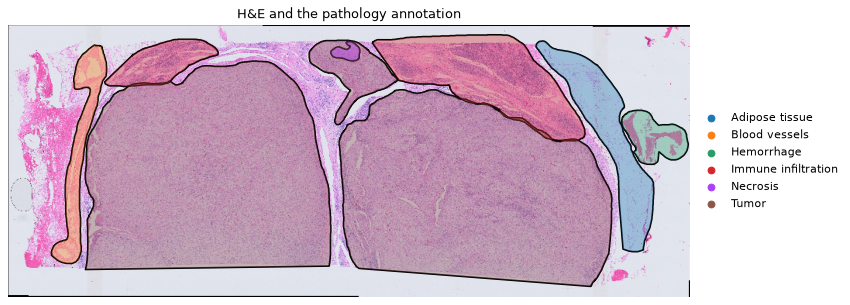

In [3]:
fig, ax = plt.subplots(figsize=(11, 10))
(
    sdata.pl.render_images("he")
    .pl.render_shapes("pathology", color="region", fill_alpha=0.35, outline_alpha=1, outline_width=1.5)
    .pl.show(coordinate_systems="global", ax=ax, title="H&E and the pathology annotation")
)
ax.set_axis_off()

Most of the section is tumor: two large nodules. Bands of immune infiltration run along the upper edge of the
tissue and between the nodules. Small areas of necrosis, fat and hemorrhage lie at the margins; the blood vessels and
the hemorrhage are outside the area measured by the Xenium, so no cells fall in them.

The table holds one row per segmented cell, with both modalities:

In [4]:
mdata = sdata["table"]
mdata

MuData object with n_obs × n_vars = 465534 × 432
  obs:	'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels'
  uns:	'spatialdata_attrs'
  obsm:	'spatial'
  2 modalities
    rna:	465534 × 405
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None
    prot:	465534 × 27
      var:	'gene_ids', 'feature_types', 'genome'
      layers:	None

## 2. Quality control

*Which cells were measured well enough to analyse, in each modality?*

### RNA: transcripts per cell and cell size

A cell with few transcripts cannot be typed reliably; a very small or very large "cell" is usually a segmentation
error (a fragment, or several cells merged). We keep cells with at least 20 transcripts and an area of 10 to 600 µm².

median transcripts per cell: 70


fewer than 20 transcripts    8.3%
area outside 10-600 µm²      1.0%
removed                      8.5%
dtype: str

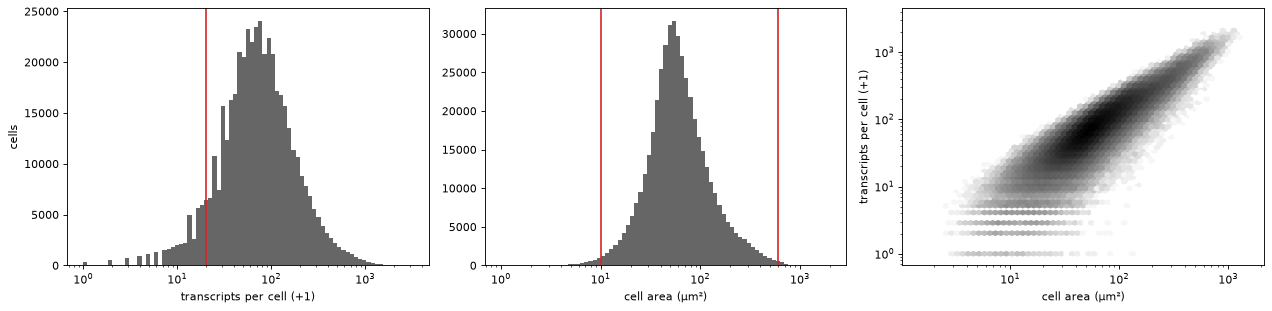

In [5]:
MIN_TRANSCRIPTS, MIN_AREA, MAX_AREA = 20, 10, 600
obs = mdata.obs
fails = pd.DataFrame({
    "fewer than 20 transcripts": obs["transcript_counts"] < MIN_TRANSCRIPTS,
    "area outside 10-600 µm²": ~obs["cell_area"].between(MIN_AREA, MAX_AREA),
})
fails["removed"] = fails.any(axis=1)

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].hist(obs["transcript_counts"] + 1, bins=np.logspace(0, 3.5, 80), color="0.4")
axs[0].axvline(MIN_TRANSCRIPTS, color="C3")
axs[0].set(xscale="log", xlabel="transcripts per cell (+1)", ylabel="cells")
axs[1].hist(obs["cell_area"], bins=np.logspace(0, 3.3, 80), color="0.4")
for x in (MIN_AREA, MAX_AREA):
    axs[1].axvline(x, color="C3")
axs[1].set(xscale="log", xlabel="cell area (µm²)")
axs[2].hexbin(obs["cell_area"], obs["transcript_counts"] + 1, xscale="log", yscale="log", gridsize=60, bins="log",
              cmap="Greys")
axs[2].set(xlabel="cell area (µm²)", ylabel="transcripts per cell (+1)")
plt.tight_layout()
print(f"median transcripts per cell: {obs['transcript_counts'].median():.0f}")
fails.mean().map("{:.1%}".format)

A median cell has 70 transcripts, from a panel of 405 genes: most genes are not detected in most cells. 8.3% of the
cells have fewer than 20 transcripts and 1% an implausible area; 8.5% are removed in all. The transcripts grow with
the cell area (right): a larger cell, or one cut through its middle, yields more transcripts of every gene, which the
normalization will account for.

### Where are the low-quality cells?

Quality is rarely uniform across a section. A map shows whether the removed cells are scattered or concentrated in a
region (for example necrosis, or a fold of the tissue), which would bias what we can say about that region.

Adipose tissue         10.7%
Immune infiltration    11.8%
Necrosis               36.3%
Tumor                   6.8%
unannotated            14.4%
Name: removed by QC, dtype: str

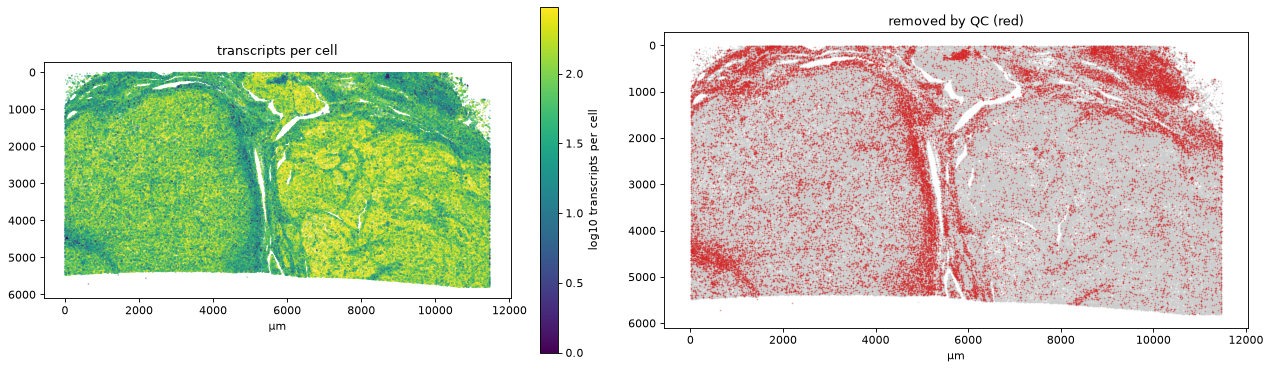

In [6]:
xy = mdata.obsm["spatial"]
fig, axs = plt.subplots(1, 2, figsize=(16, 7.5))
im = axs[0].scatter(xy[:, 0], xy[:, 1], c=np.log10(obs["transcript_counts"] + 1), s=0.05, cmap="viridis",
                    vmax=np.log10(300), rasterized=True)
fig.colorbar(im, ax=axs[0], shrink=0.6, label="log10 transcripts per cell")
axs[0].set_title("transcripts per cell")
removed = fails["removed"].to_numpy()
axs[1].scatter(xy[~removed, 0], xy[~removed, 1], s=0.05, color="0.8", rasterized=True)
axs[1].scatter(xy[removed, 0], xy[removed, 1], s=0.05, color="C3", rasterized=True)
axs[1].set_title("removed by QC (red)")
for ax in axs:
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("µm")
plt.tight_layout()

mdata.obs["pathology"] = pd.Categorical(helpers.pathology_region(sdata))
fails.groupby(mdata.obs["pathology"].to_numpy())["removed"].mean().map("{:.1%}".format).rename("removed by QC")

The removed cells are not spread evenly. They concentrate in the fibrous bands between the tumor nodules and along
the upper edge, where cells are small and poor in transcripts: the immune infiltrate loses 12% of its cells, the tumor
7%, the small necrotic areas a third (table). Comparisons between the two regions are therefore made on somewhat fewer, and larger,
immune-infiltrate cells.

### Protein: what does each stain measure?

Each protein value is the mean intensity of a stain over the cell, after subtraction of the background. A value of 0
means "not above background". The fraction of cells above background and the spread of the values tell whether a
marker separates positive from negative cells.

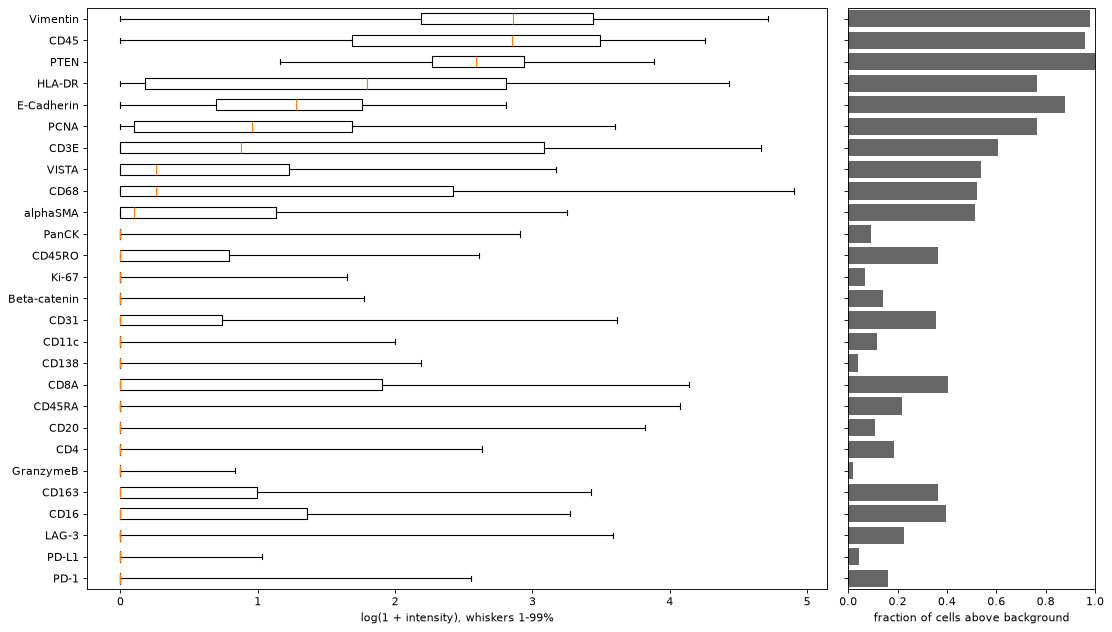

In [7]:
prot = mdata.mod["prot"]
intensity = pd.DataFrame(prot.X.toarray() if hasattr(prot.X, "toarray") else np.asarray(prot.X),
                         index=prot.obs_names, columns=prot.var_names)
order = intensity.median().sort_values().index
fig, axs = plt.subplots(1, 2, figsize=(14, 8), sharey=True, gridspec_kw={"width_ratios": [3, 1]})
axs[0].boxplot([np.log1p(intensity[p]) for p in order], orientation="horizontal", showfliers=False, whis=(1, 99))
axs[0].set(yticks=range(1, len(order) + 1), yticklabels=order, xlabel="log(1 + intensity), whiskers 1-99%")
axs[1].barh(range(1, len(order) + 1), (intensity[order] > 0).mean(), color="0.4")
axs[1].set(xlabel="fraction of cells above background", xlim=(0, 1))
plt.tight_layout()

There are two kinds of markers. Vimentin, CD45, PTEN, HLA-DR, E-cadherin and PCNA are above background in most cells:
their information lies in how much, not whether. The lineage and state markers are sparse: CD20, CD4, CD138, Ki-67,
PD-L1 and granzyme B are above background in 2 to 20% of the cells, as expected for rare cell types and states.
CD45 above background in 96% of the cells is more than the share of immune cells, so a low CD45 value is not the same
as CD45 negative. We therefore use the markers together, to define clusters, rather than with a threshold each.

### The stains themselves

Numbers per cell are only as good as the images behind them. A crop of a few stains shows whether the signal is
membranous or cytoplasmic as expected, and whether it is specific.

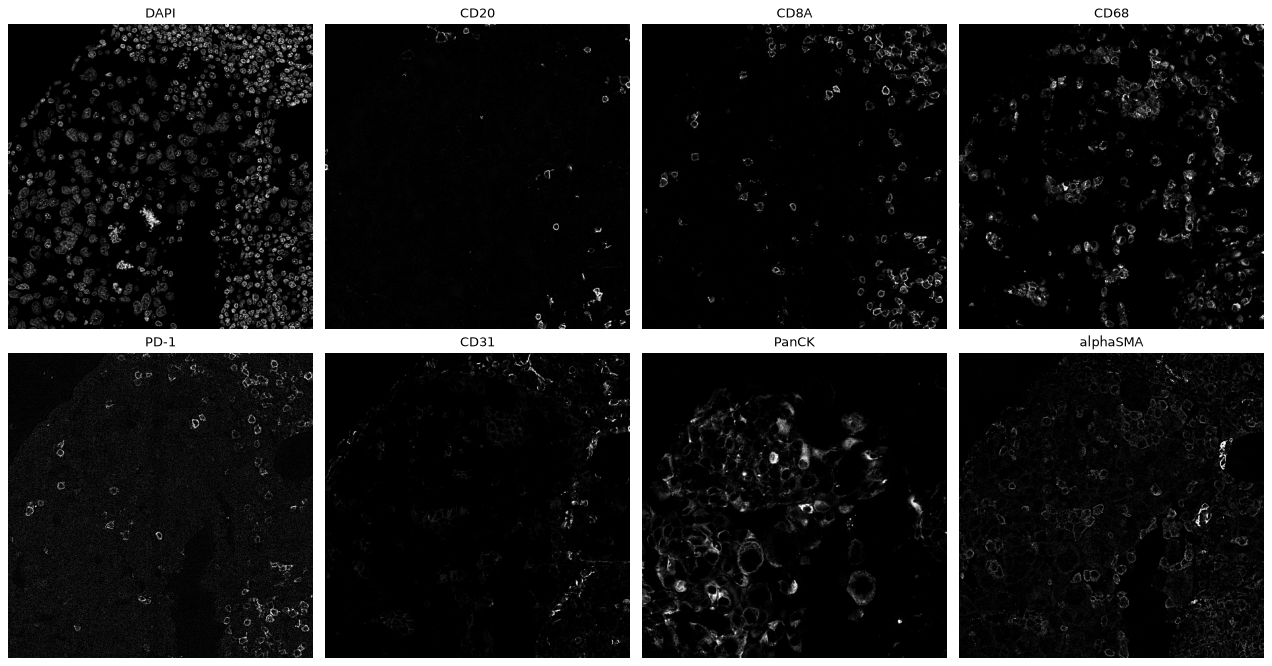

In [8]:
# a 400 µm window at the center of the tissue
cx, cy = np.median(xy, axis=0) / helpers.PIXEL_SIZE
half = 200 / helpers.PIXEL_SIZE
crop = sdata.query.bounding_box(axes=("x", "y"), min_coordinate=[cx - half, cy - half],
                                max_coordinate=[cx + half, cy + half], target_coordinate_system="global")
channels = ["DAPI", "CD20", "CD8A", "CD68", "PD-1", "CD31", "PanCK", "alphaSMA"]  # 8 of the 27 stains
fig, axs = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, channel in zip(axs.flat, channels, strict=True):
    pixels = crop["stains"]["scale0"]["image"].sel(c=channel).data[::4, ::4].compute()
    norm = plt.Normalize(*np.percentile(pixels, [50, 99.9]))  # black at the background, white at the brightest cells
    crop.pl.render_images("stains", channel=channel, cmap="gray", norm=norm, colorbar=False).pl.show(
        coordinate_systems="global", ax=ax, title=channel)
    ax.set_axis_off()
plt.tight_layout()

The stains look as expected: DAPI marks every nucleus, CD8A outlines a scattered population of small cells, CD68 the
larger macrophages, PanCK a nest of epithelial tumor cells, CD31 thin vessel walls. CD20 and alphaSMA have little
signal here: the window lies inside the tumor, where B cells and smooth muscle are rare.

We apply the QC filter to the table. Both modalities are filtered together, since they describe the same cells.

In [9]:
mu.pp.filter_obs(mdata, "transcript_counts", lambda x: x >= MIN_TRANSCRIPTS)
mu.pp.filter_obs(mdata, "cell_area", lambda x: (x >= MIN_AREA) & (x <= MAX_AREA))
print(mdata.n_obs, "cells kept")
mdata.obs["pathology"].value_counts()

425878 cells kept


pathology
Tumor                  310078
Immune infiltration     84220
unannotated             30379
Necrosis                  827
Adipose tissue            374
Name: count, dtype: int64

## 3. Normalization

*How do we make cells, and the two modalities, comparable?*

- **RNA**: a larger cell, or one cut through its middle, yields more transcripts of every gene. Dividing by the total
  per cell (and scaling to the median total) removes this, and a log transform tempers the few very high counts.
- **Protein**: the values are already *mean* intensities, so cell size does not inflate them in the same way. Stains
  differ in brightness by orders of magnitude, so we log transform and then scale each marker to mean 0 and
  variance 1, so that bright stains do not dominate the dim ones.

The plots check the first point: transcripts grow with cell area, mean stain intensity much less.

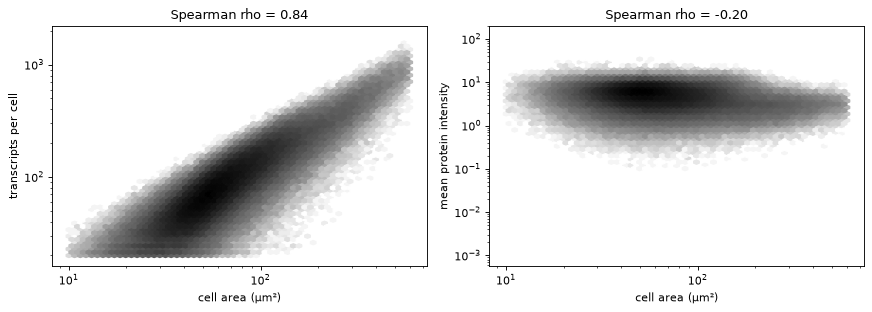

In [10]:
from scipy.stats import spearmanr

rna, prot = mdata.mod["rna"], mdata.mod["prot"]
area = mdata.obs["cell_area"].to_numpy()
total_rna = np.asarray(rna.X.sum(axis=1)).ravel()
mean_prot = np.asarray(prot.X.mean(axis=1)).ravel()
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, label in [(axs[0], total_rna, "transcripts per cell"), (axs[1], mean_prot + 1e-3, "mean protein intensity")]:
    ax.hexbin(area, values, xscale="log", yscale="log", gridsize=60, bins="log", cmap="Greys")
    rho = spearmanr(area, values).statistic
    ax.set(xlabel="cell area (µm²)", ylabel=label, title=f"Spearman rho = {rho:.2f}")
plt.tight_layout()

Transcripts per cell grow almost in proportion to the cell area (rho 0.84); the mean protein intensity does not
(rho -0.20). The RNA needs the per-cell normalization, the protein does not.

In [11]:
rna.obs["cell_id"] = mdata.obs["cell_id"].to_numpy()
helpers.normalize(rna, prot)  # raw values kept in rna.layers["counts"] and prot.layers["intensity"]

## 4. Joint models of RNA and protein

*What structure is shared by the two modalities, and what is specific to one of them? And is modelling them jointly
worth it?*

We use two joint models:

- **MOFA+** decomposes both modalities into a few *factors*, axes of variation along which cells differ. For each
  factor it reports how much of the variance of each modality it explains, so a factor can be shared by RNA and
  protein or specific to one of them.
- **totalVI** (scvi-tools) learns a joint low-dimensional representation of each cell with a neural network.

Both were trained on a GPU on all cells; the notebook loads their results from `cache/` unless `RETRAIN` is set.

In [12]:
if RETRAIN:
    helpers.train_totalvi(rna, prot, CACHE / "totalvi.npz")
    helpers.train_mofa(rna, prot, CACHE / "mofa.npz")


def cached(name):
    """A cached result and the position of each cell of the table in it."""
    result = np.load(CACHE / f"{name}.npz")
    position = pd.Index(result["cell_id"]).get_indexer(mdata.obs["cell_id"].astype(str))
    assert (position >= 0).all(), f"{name}: cells missing from the cache, set RETRAIN = True"
    return result, position


mofa, position = cached("mofa")
mdata.obsm["X_mofa"] = mofa["factors"][position].astype(np.float32)
totalvi, position = cached("totalvi")
mdata.obsm["X_totalvi"] = totalvi["latent"][position].astype(np.float32)

### Which factors are shared, which are specific?

total variance explained (%): {'RNA': 30.700000762939453, 'protein': 70.19999694824219}


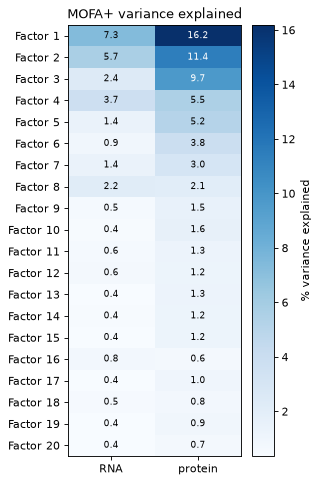

In [13]:
r2 = pd.DataFrame({"RNA": mofa["r2_rna"], "protein": mofa["r2_prot"]},
                  index=[f"Factor {i + 1}" for i in range(len(mofa["r2_rna"]))])
fig, ax = plt.subplots(figsize=(3.5, 7))
im = ax.imshow(r2.to_numpy(), cmap="Blues", aspect="auto")
ax.set(xticks=[0, 1], xticklabels=r2.columns, yticks=range(len(r2)), yticklabels=r2.index)
for (i, j), v in np.ndenumerate(r2.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="w" if v > r2.to_numpy().max() / 2 else "k")
fig.colorbar(im, ax=ax, label="% variance explained")
ax.set_title("MOFA+ variance explained")
print("total variance explained (%):", r2.sum().round(1).to_dict())

With 20 factors, MOFA+ explains 70% of the protein variance and 31% of the RNA variance. The RNA share is lower
because counts of a sparse panel are noisy: much of their variance is sampling noise, which no factor can explain. The
leading factors explain variance in both modalities: the main axes along which cells differ are seen by RNA and
protein alike. No factor is specific to one modality.

### What do the main factors capture?

The features with the largest weights, per modality, name a factor.

In [14]:
weights = {"RNA": pd.DataFrame(mofa["weights_rna"], index=mofa["genes"], columns=r2.index),
           "protein": pd.DataFrame(mofa["weights_prot"], index=mofa["proteins"], columns=r2.index)}


def top_features(factor, n_genes=6, n_proteins=4):
    out = {}
    for view, n in [("RNA", n_genes), ("protein", n_proteins)]:
        w = weights[view][factor]
        out[f"{view} +"] = ", ".join(w.nlargest(n).index)
        out[f"{view} -"] = ", ".join(w.nsmallest(n).index)
    return out


main_factors = r2.sum(axis=1).nlargest(8).index
pd.DataFrame({f: top_features(f) for f in main_factors}).T.assign(**{"% RNA": r2["RNA"], "% protein": r2["protein"]}
                                                                    ).loc[main_factors].round(1)

,RNA +,RNA -,protein +,protein -,% RNA,% protein
Factor 1,"HLA-DRA, PTPRC, FCGR3A, HLA-DRB1, MS4A6A, FCGR3B","VIM, ACTA2, CAVIN1, VCAN, MYLK, ADAMTS1","CD45, HLA-DR, CD68, CD163","PTEN, Beta-catenin, CD31, Vimentin",7.3,16.200001
Factor 2,"PTPRC, CD3E, CXCR4, CD8A, TRAC, IL7R","FCGR3A, HLA-DRA, FCGR3B, VIM, CD68, HLA-DRB1","CD3E, CD45RA, CD45RO, CD8A","CD68, CD16, CD163, HLA-DR",5.7,11.400000
Factor 3,"MS4A1, CD79A, BANK1, CXCR4, HLA-DRA, IRF8","CD8A, PECAM1, CCL5, CD3E, CD2, GZMK","CD20, CD45RA, PanCK, CD11c","CD8A, LAG-3, PD-1, CD45RO",2.4,9.700000
Factor 4,"PECAM1, CD93, VWF, ADGRL4, APOLD1, CD34","CXCL6, VIM, MET, VCAN, SEMA3C, KRT8","CD31, Beta-catenin, VISTA, CD163","PanCK, PCNA, LAG-3, PD-1",3.7,5.500000
Factor 5,"MS4A1, VIM, ACTA2, HLA-DRA, CD34, BANK1","MZB1, TENT5C, SLAMF7, SDC1, FKBP11, PRDM1","alphaSMA, Vimentin, PTEN, CD20","CD138, CD3E, CD4, VISTA",1.4,5.200000
Factor 6,"TNC, CD8A, MMRN1, CCL5, LYVE1, PROX1","ACTA2, IL7R, VIM, PDGFRB, MYLK, PTEN","LAG-3, PD-1, CD8A, GranzymeB","E-Cadherin, alphaSMA, CD4, Vimentin",0.9,3.800000
Factor 7,"IL7R, PTPRC, CD3E, SELL, CD93, TRAC","MZB1, SLAMF7, TENT5C, ACTA2, PDGFRB, COL5A2","CD4, CD11c, CD45RO, VISTA","CD138, alphaSMA, LAG-3, PD-1",1.4,3.000000
Factor 8,"PECAM1, MET, CXCL6, VWF, CD34, ADGRL4","TNC, ACTA2, PDGFRB, CRISPLD2, COL5A2, THBS2","CD31, PCNA, CD138, Beta-catenin","alphaSMA, CD4, CD163, VISTA",2.2,2.100000


The weights name the factors. Factor 1 separates immune, in particular myeloid, cells (HLA-DR, CD45, CD68, CD163
protein; *HLA-DRA*, *PTPRC*, *FCGR3A* transcripts) from stromal cells (vimentin, alphaSMA, *VCAN*). Factor 2 separates
T cells (CD3E, CD8A; *CD3E*, *TRAC*) from myeloid cells, Factor 3 B cells (CD20; *MS4A1*, *CD79A*) from CD8 T cells,
Factor 4 endothelium (CD31; *PECAM1*, *VWF*) from tumor cells (*CXCL6*, *MET*). Factor 6 is a T cell state: LAG-3,
PD-1 and granzyme B protein. Within each factor the two modalities point to the same cells, which is what a shared
factor means.

### Where are the factors active in the tissue?

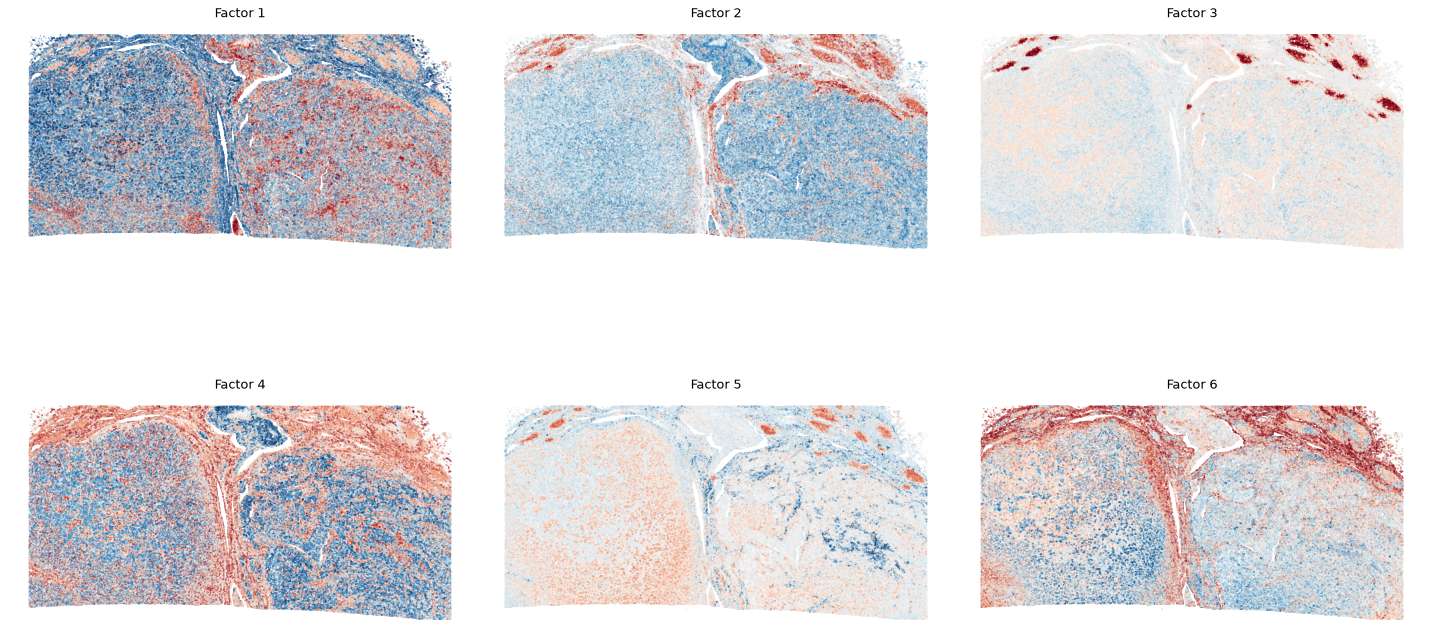

In [15]:
xy = mdata.obsm["spatial"]
fig, axs = plt.subplots(2, 3, figsize=(18, 11))
for ax, factor in zip(axs.flat, main_factors[:6], strict=True):
    values = mdata.obsm["X_mofa"][:, r2.index.get_loc(factor)]
    lo, hi = np.percentile(values, [1, 99])
    ax.scatter(xy[:, 0], xy[:, 1], c=values, s=0.03, cmap="RdBu_r", vmin=-max(-lo, hi), vmax=max(-lo, hi),
               rasterized=True)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_axis_off()
    ax.set_title(factor)
plt.tight_layout()

In the tissue, Factor 3 (B cells) lights up round aggregates along the upper edge: B cell follicles, the hallmark of
tertiary lymphoid structures. Factor 4 (endothelium against tumor) is low inside the tumor nodules and high in the
bands between them. Factor 1 differs between the two nodules, higher in the right one: the nodules differ in their
myeloid content.

### Is it worth modelling RNA and protein jointly?

To answer this without labels, the benchmark in `../benchmark` hides some proteins and genes from every method, and
asks how well each method's representation of a cell predicts the hidden values (from the cell's 20 nearest
neighbors), and the cell's pathology region. Higher is better on all three.

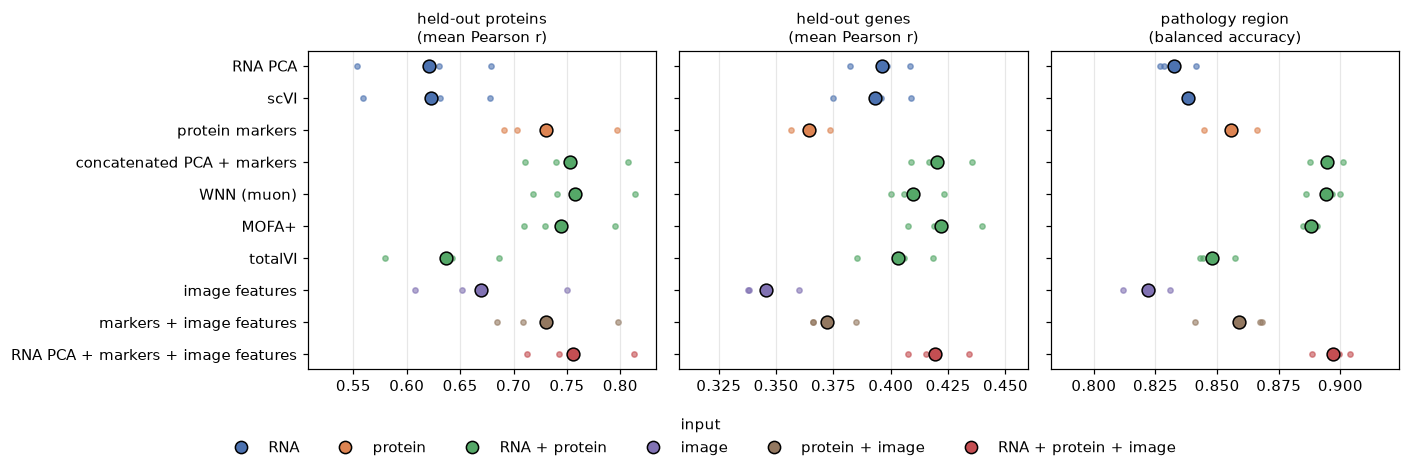

In [16]:
Image("../benchmark/results/benchmark.png")

## 5. Cell types

*Which cell types are there, and how do RNA and protein define them?*

We cluster the cells on the simplest joint representation, which the benchmark found as good as the models: the
principal components of the RNA next to the protein markers, each modality scaled to the same total variance.

In [17]:
sc.tl.pca(rna, n_comps=20, random_state=0)
blocks = [rna.obsm["X_pca"], np.asarray(prot.X)]
mdata.obsm["X_joint"] = np.hstack([b / np.sqrt(b.var(axis=0).sum()) for b in blocks]).astype(np.float32)

clusters_file = CACHE / "leiden.npz"
if RETRAIN or not clusters_file.exists():
    joint = ad.AnnData(obs=mdata.obs[[]], obsm={"X_joint": mdata.obsm["X_joint"]})
    sc.pp.neighbors(joint, use_rep="X_joint", n_neighbors=15, random_state=0)
    sc.tl.leiden(joint, resolution=1.0, flavor="igraph", n_iterations=2, random_state=0)
    np.savez_compressed(clusters_file, cell_id=mdata.obs["cell_id"].to_numpy().astype(str),
                        leiden=joint.obs["leiden"].astype(int).to_numpy())
clusters, position = cached("leiden")
mdata.obs["leiden"] = pd.Categorical(clusters["leiden"][position].astype(str),
                                     categories=[str(c) for c in np.unique(clusters["leiden"])])
mdata.obs["leiden"].value_counts().sort_index().to_frame().T

leiden,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
count,41747,25687,12926,34883,57296,35393,12923,3781,10936,21506,22207,31993,3373,25362,7344,15912,15245,1620,39673,6071


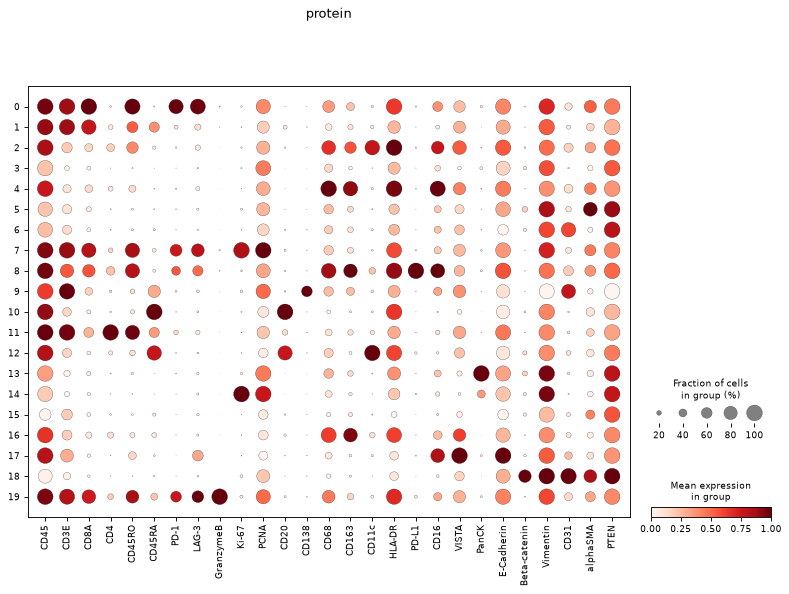

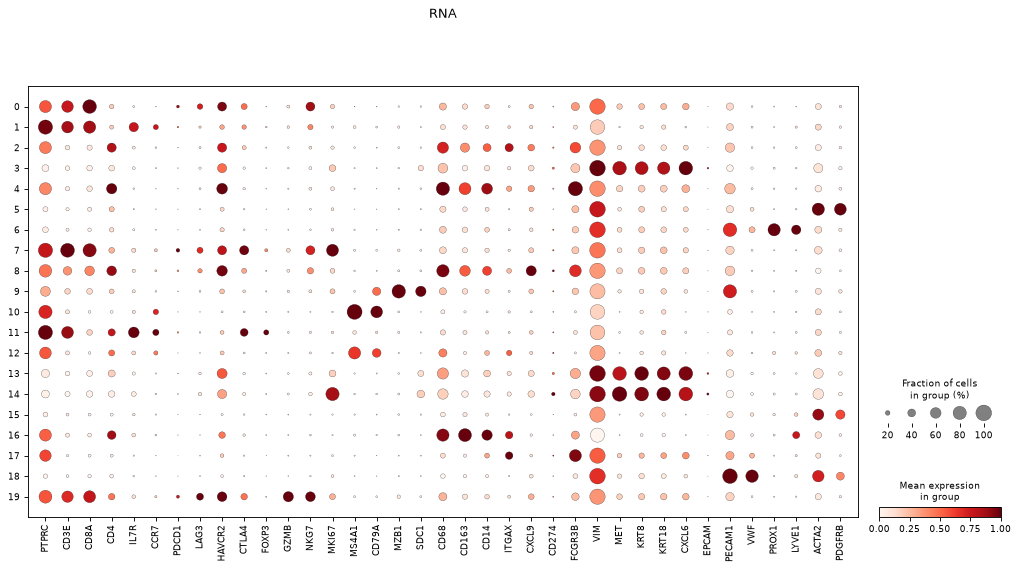

In [18]:
PROTEIN_MARKERS = ["CD45", "CD3E", "CD8A", "CD4", "CD45RO", "CD45RA", "PD-1", "LAG-3", "GranzymeB", "Ki-67", "PCNA",
                   "CD20", "CD138", "CD68", "CD163", "CD11c", "HLA-DR", "PD-L1", "CD16", "VISTA", "PanCK",
                   "E-Cadherin", "Beta-catenin", "Vimentin", "CD31", "alphaSMA", "PTEN"]
RNA_MARKERS = ["PTPRC", "CD3E", "CD8A", "CD4", "IL7R", "CCR7", "PDCD1", "LAG3", "HAVCR2", "CTLA4", "FOXP3", "GZMB",
               "NKG7", "MKI67", "MS4A1", "CD79A", "MZB1", "SDC1", "CD68", "CD163", "CD14", "ITGAX", "CXCL9", "CD274",
               "FCGR3B", "VIM", "MET", "KRT8", "KRT18", "CXCL6", "EPCAM", "PECAM1", "VWF", "PROX1", "LYVE1", "ACTA2",
               "PDGFRB"]
RNA_MARKERS = [g for g in RNA_MARKERS if g in rna.var_names]

# proteins on the log scale before z-scoring, so that the dot size (fraction above background) is meaningful
prot_view = ad.AnnData(np.log1p(prot.layers["intensity"]), obs=mdata.obs[["leiden"]], var=prot.var)
rna.obs["leiden"] = mdata.obs["leiden"].values  # a Categorical, so that the clusters stay groups
sc.pl.dotplot(prot_view, PROTEIN_MARKERS, groupby="leiden", standard_scale="var", title="protein")
sc.pl.dotplot(rna, RNA_MARKERS, groupby="leiden", standard_scale="var", title="RNA")

**Reading the dotplots.** Each row is a cluster, each column a marker; the color is the mean (scaled per marker), the
dot size the fraction of cells with signal. The two modalities support each other: the clusters with CD8A protein
are the ones with *CD8A* transcripts, the B cell cluster has both CD20 protein and *MS4A1* RNA. They also complement
each other. Some states are visible in one modality only: PD-1 and LAG-3 protein mark a CD8 T cell cluster whose
*PDCD1* transcripts are almost absent, while the RNA separates endothelial subtypes (*PROX1*, *LYVE1*, *VWF*) that a
single CD31 stain cannot. The panel has no classical ccRCC tumor markers (*CA9*, *PAX8*, *NDUFA4L2*); the tumor cells
are recognised by *VIM*, *MET*, *KRT8* and *CXCL6* transcripts, PanCK protein, low CD45 and their location in the
tumor region.

We name the clusters from these markers:

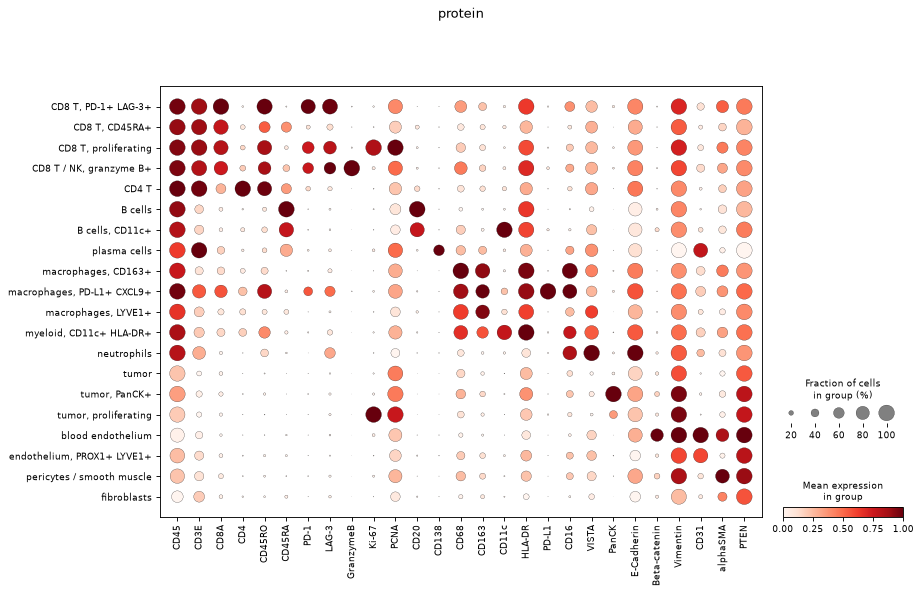

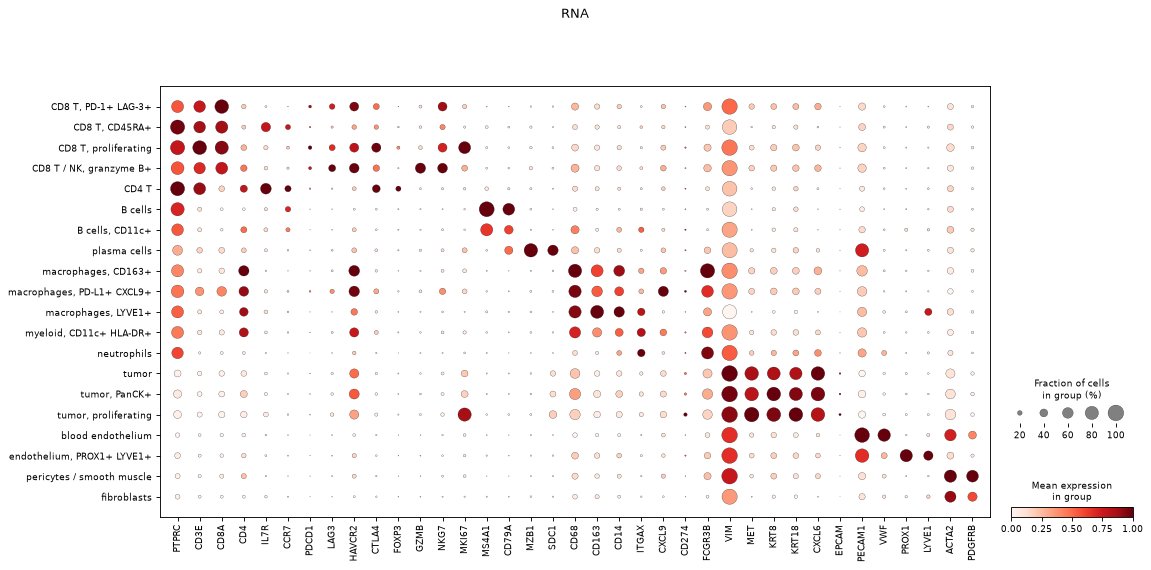

In [19]:
CELL_TYPES = {
    "0": "CD8 T, PD-1+ LAG-3+",
    "1": "CD8 T, CD45RA+",
    "7": "CD8 T, proliferating",
    "19": "CD8 T / NK, granzyme B+",
    "11": "CD4 T",
    "10": "B cells",
    "12": "B cells, CD11c+",
    "9": "plasma cells",
    "4": "macrophages, CD163+",
    "8": "macrophages, PD-L1+ CXCL9+",
    "16": "macrophages, LYVE1+",
    "2": "myeloid, CD11c+ HLA-DR+",
    "17": "neutrophils",
    "3": "tumor",
    "13": "tumor, PanCK+",
    "14": "tumor, proliferating",
    "18": "blood endothelium",
    "6": "endothelium, PROX1+ LYVE1+",
    "5": "pericytes / smooth muscle",
    "15": "fibroblasts",
}
assert set(CELL_TYPES) == set(mdata.obs["leiden"].cat.categories), "the clusters changed: revisit the annotation"
COMPARTMENT = {"CD8 T": "T cells", "CD4 T": "T cells", "B cells": "B and plasma cells",
               "plasma cells": "B and plasma cells", "macrophages": "myeloid", "myeloid": "myeloid",
               "neutrophils": "myeloid", "tumor": "tumor", "blood endothelium": "vessels and stroma",
               "endothelium": "vessels and stroma", "pericytes": "vessels and stroma", "fibroblasts": "vessels and stroma"}
order = list(CELL_TYPES.values())
mdata.obs["cell_type"] = pd.Categorical(mdata.obs["leiden"].map(CELL_TYPES), categories=order)
mdata.obs["compartment"] = mdata.obs["cell_type"].map(
    lambda t: next(v for k, v in COMPARTMENT.items() if t.startswith(k))).astype("category")
rna.obs["cell_type"] = mdata.obs["cell_type"].values
prot_view.obs["cell_type"] = mdata.obs["cell_type"].values
sc.pl.dotplot(prot_view, PROTEIN_MARKERS, groupby="cell_type", standard_scale="var", title="protein")
sc.pl.dotplot(rna, RNA_MARKERS, groupby="cell_type", standard_scale="var", title="RNA")

With names, the dotplots read as a table of the cell types. One signal we cannot explain: the plasma cells show CD3E
protein, which neither their RNA nor their biology supports. It may be cross-reactivity of the antibody or signal from
neighboring T cells; we flag it rather than interpret it.

### The joint representations, seen in two dimensions

A UMAP of 50,000 random cells, computed from the joint representation used for clustering and from the totalVI
latent space. If both representations capture the same biology, the cell types should form similar groups in both.

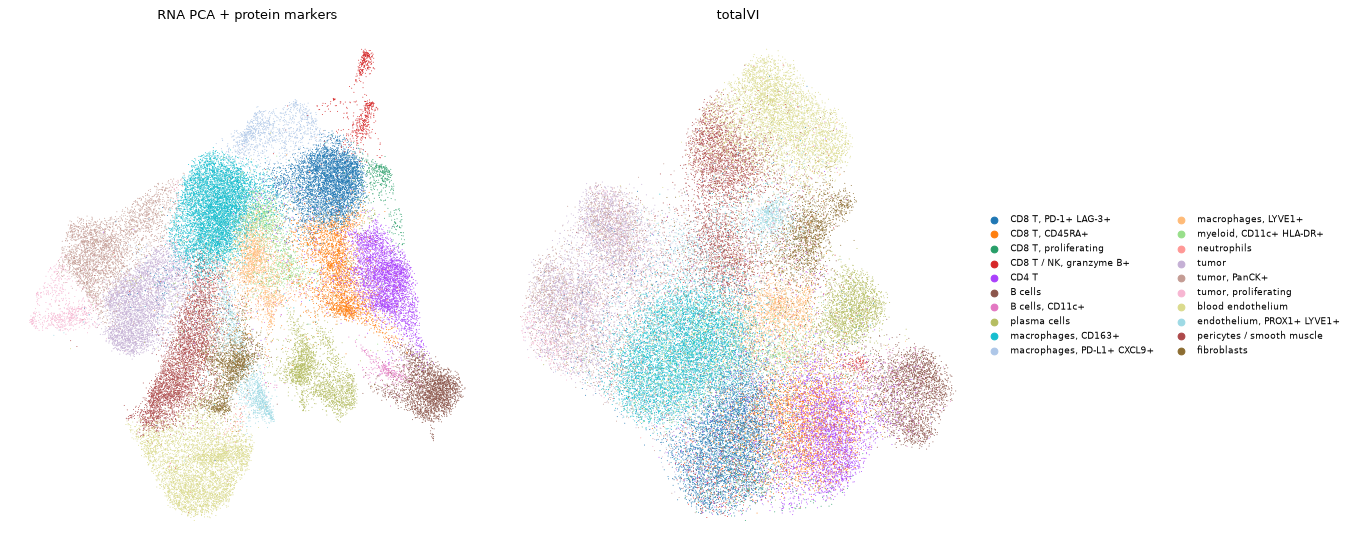

In [20]:
rng = np.random.default_rng(0)
sample = np.sort(rng.choice(mdata.n_obs, 50_000, replace=False))
fig, axs = plt.subplots(1, 2, figsize=(17, 7))
for ax, rep, title in [(axs[0], "X_joint", "RNA PCA + protein markers"), (axs[1], "X_totalvi", "totalVI")]:
    view = ad.AnnData(obs=mdata.obs.iloc[sample][["cell_type"]], obsm={rep: mdata.obsm[rep][sample]})
    sc.pp.neighbors(view, use_rep=rep, random_state=0)
    sc.tl.umap(view, random_state=0)
    sc.pl.umap(view, color="cell_type", ax=ax, show=False, title=title,
               legend_loc="right margin" if ax is axs[1] else "none", legend_fontsize=8, size=3, frameon=False)
plt.tight_layout()

Both representations separate the same main groups: tumor, vessels and stroma, myeloid cells, B and plasma cells,
T cells. They differ within the T cells: the joint representation used for clustering separates the CD8 T cell
states and the CD4 T cells, while in the totalVI space the PD-1+ LAG-3+ CD8 T cells mix with the CD4 and CD45RA+
T cells. These states are defined mainly by proteins, which totalVI models as counts, a poor fit for stain
intensities (see the benchmark).

## 6. How are the immune cells organised relative to the tumor?

### Which cells live where?

The pathologist marked the tumor and, separately, areas of dense immune infiltration. For each cell type, which
fraction of its cells sits in each region?

pathology,Tumor,Immune infiltration
cell_type,,
"CD8 T, PD-1+ LAG-3+",0.98,0.02
"CD8 T, CD45RA+",0.48,0.52
"CD8 T, proliferating",0.86,0.14
"CD8 T / NK, granzyme B+",0.86,0.14
CD4 T,0.44,0.56
B cells,0.06,0.94
"B cells, CD11c+",0.07,0.93
plasma cells,0.83,0.17
"macrophages, CD163+",0.99,0.01


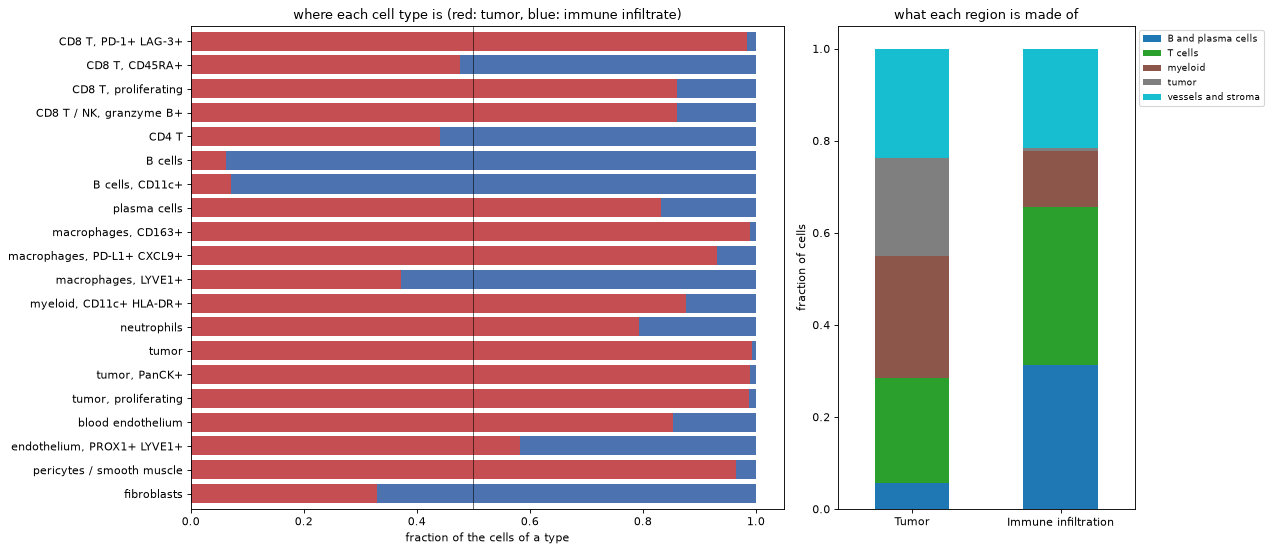

In [21]:
regions = ["Tumor", "Immune infiltration"]
in_region = mdata.obs[mdata.obs["pathology"].isin(regions)]
location = pd.crosstab(in_region["cell_type"], in_region["pathology"].astype(str), normalize="index")[regions]
composition = pd.crosstab(in_region["pathology"].astype(str), in_region["compartment"], normalize="index").loc[regions]

fig, axs = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [2, 1]})
location.plot.barh(stacked=True, ax=axs[0], color=["#C44E52", "#4C72B0"], width=0.8, legend=False)
axs[0].invert_yaxis()
axs[0].axvline(0.5, color="k", lw=0.5)
axs[0].set(xlabel="fraction of the cells of a type", ylabel="", title="where each cell type is (red: tumor, blue: immune infiltrate)")
composition.plot.bar(stacked=True, ax=axs[1], colormap="tab10", rot=0)
axs[1].set(ylabel="fraction of cells", xlabel="", title="what each region is made of")
axs[1].legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
location.round(2)

The two regions are organised differently. The PD-1+ LAG-3+ CD8 T cells (98% in the tumor), the PD-L1+ macrophages
(93%) and the CD163+ macrophages (99%) are in the tumor, with the tumor cells. The B cells (94% in the immune
infiltrate), the CD11c+ B cells, the fibroblasts and the LYVE1+ macrophages are mostly in the immune infiltrate. A
third of the infiltrate is B and plasma cells and a third T cells; inside the tumor, myeloid cells are as frequent as T
cells.

Only about a fifth of the cells in the tumor region were typed as tumor cells. ccRCC is rich in vessels and immune
cells, but this also reflects the panel: without the classical ccRCC markers, tumor cells are recognised by few
transcripts and by what they lack, and a tumor cell picking up some myeloid or endothelial signal from its neighbors is
likely assigned to that type.

### Do CD8 T cells differ between the tumor and the immune infiltrate?

cell_type,"CD8 T / NK, granzyme B+","CD8 T, CD45RA+","CD8 T, PD-1+ LAG-3+","CD8 T, proliferating"
pathology,,,,
Tumor,0.08,0.18,0.69,0.05
Immune infiltration,0.06,0.86,0.05,0.04


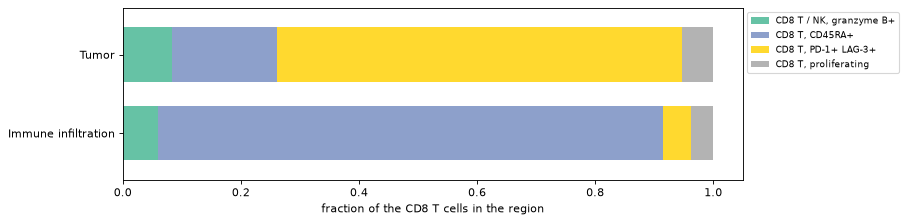

In [22]:
cd8 = in_region[in_region["cell_type"].astype(str).str.startswith("CD8 T")]
states = pd.crosstab(cd8["pathology"].astype(str), cd8["cell_type"].astype(str), normalize="index").loc[regions]
ax = states.plot.barh(stacked=True, figsize=(10, 2.8), colormap="Set2", width=0.7)
ax.invert_yaxis()
ax.set(xlabel="fraction of the CD8 T cells in the region", ylabel="")
ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
states.round(2)

The CD8 T cells are in different states in the two regions. In the tumor, 69% are PD-1+ LAG-3+, the state of
chronically stimulated, exhausted T cells. In the immune infiltrate 86% are CD45RA+, a naive or early memory state,
and only 5% are PD-1+ LAG-3+. Proliferating and granzyme B+ CD8 T cells are about as frequent in both.

### Who are the neighbors of the PD-L1+ macrophages?

PD-L1 on a macrophage can switch off a T cell that carries its receptor, PD-1, but only if the two cells touch. For
each cell type we count, among the cells within 20 µm of a cell, the fraction that are PD-1+ CD8 T cells.

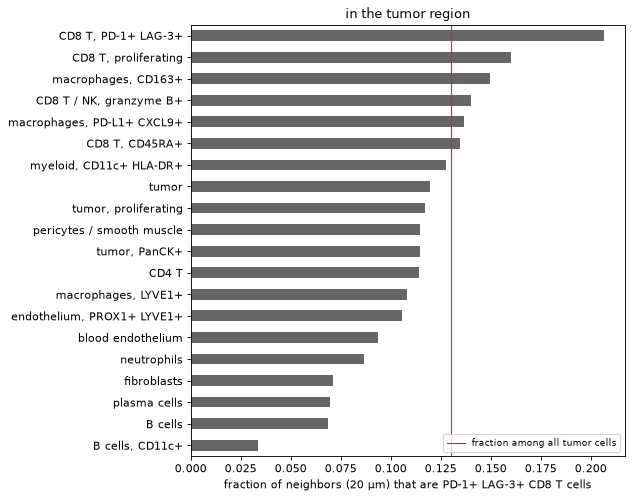

In [23]:
from sklearn.neighbors import NearestNeighbors

xy = mdata.obsm["spatial"]
neighbors = NearestNeighbors(radius=20).fit(xy).radius_neighbors(xy, return_distance=False)
is_pd1_cd8 = (mdata.obs["cell_type"] == "CD8 T, PD-1+ LAG-3+").to_numpy()
pd1_neighbors = np.array([is_pd1_cd8[n[n != i]].mean() if len(n) > 1 else np.nan for i, n in enumerate(neighbors)])
tumor_only = (mdata.obs["pathology"] == "Tumor").to_numpy()
contact = (pd.Series(pd1_neighbors[tumor_only], index=mdata.obs["cell_type"][tumor_only].to_numpy())
           .groupby(level=0, observed=True).mean().sort_values())
ax = contact.plot.barh(figsize=(7, 7), color="0.4")
ax.axvline(is_pd1_cd8[tumor_only].mean(), color="C3", lw=1, label="fraction among all tumor cells")
ax.set(xlabel="fraction of neighbors (20 µm) that are PD-1+ LAG-3+ CD8 T cells", ylabel="",
       title="in the tumor region")
ax.legend(fontsize=8, loc="lower right")

PD-1+ LAG-3+ CD8 T cells are mostly next to each other: they make up 21% of each other's neighbors, against 13% around
an average cell of the tumor. Proliferating CD8 T cells and CD163+ macrophages come next. The PD-L1+ macrophages are
only slightly enriched (14%): in this section they are near the PD-1+ T cells, as both are in the tumor, but not
preferentially in contact with them. Counting neighbors cannot tell whether two cells interact.

### Looking at the cells

A window of the tumor where PD-L1+ macrophages and PD-1+ CD8 T cells are most frequent: the H&E, two of the stains
behind the protein values, and the cell types drawn on the segmentation.

window at x = 4402, y = 4804 µm: 604 cells of interest


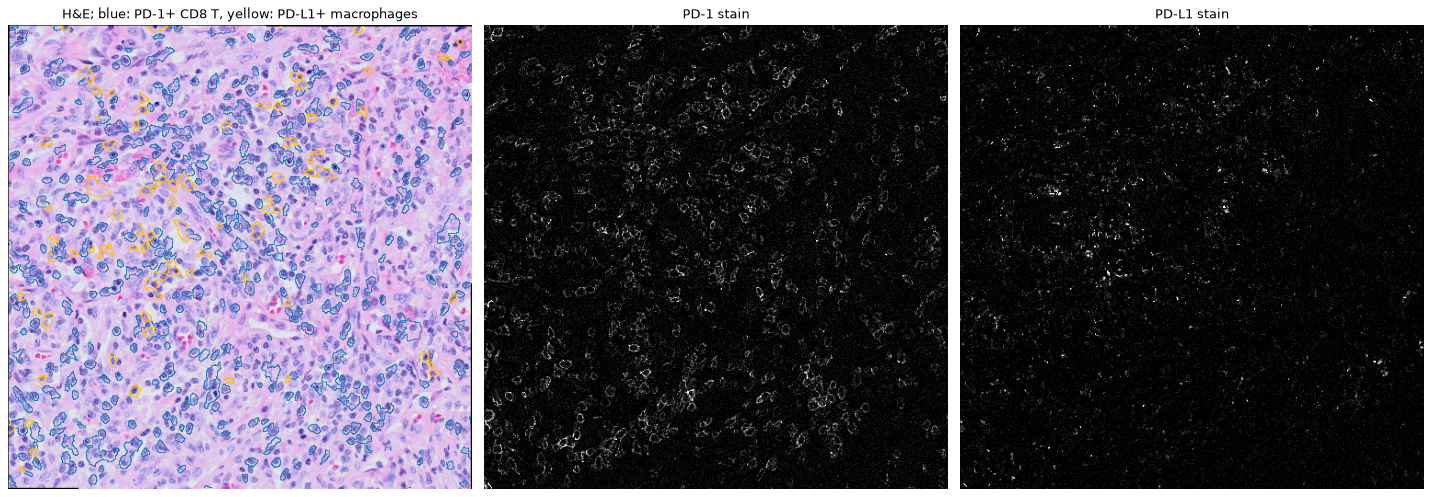

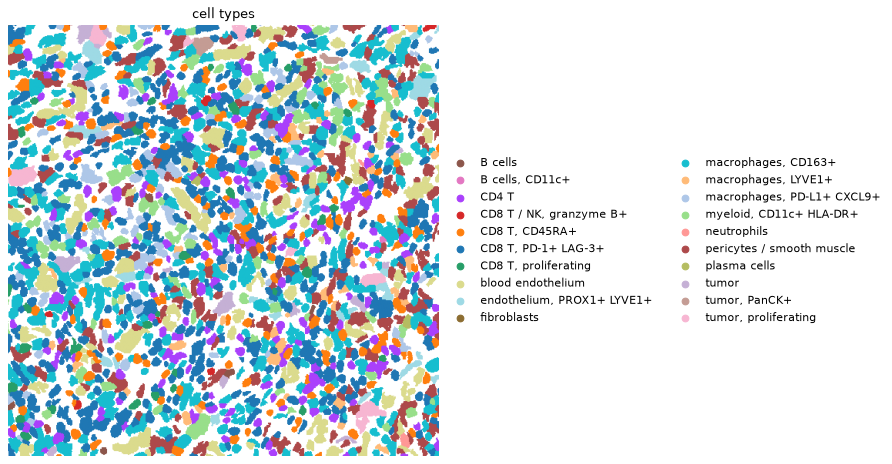

In [24]:
# the 400 µm window of the tumor with most PD-L1+ macrophages and PD-1+ CD8 T cells
size = 400
of_interest = mdata.obs["cell_type"].isin(["CD8 T, PD-1+ LAG-3+", "macrophages, PD-L1+ CXCL9+"]).to_numpy() & tumor_only
counts, xedges, yedges = np.histogram2d(xy[of_interest, 0], xy[of_interest, 1],
                                        bins=[np.arange(xy[:, 0].min(), xy[:, 0].max() + size, size)] * 1
                                        + [np.arange(xy[:, 1].min(), xy[:, 1].max() + size, size)])
i, j = np.unravel_index(counts.argmax(), counts.shape)
lo = np.array([xedges[i], yedges[j]]) / helpers.PIXEL_SIZE
window = sdata.query.bounding_box(axes=("x", "y"), min_coordinate=lo, max_coordinate=lo + size / helpers.PIXEL_SIZE,
                                  target_coordinate_system="global")
print(f"window at x = {xedges[i]:.0f}, y = {yedges[j]:.0f} µm: {int(counts[i, j])} cells of interest")

interest = ["CD8 T, PD-1+ LAG-3+", "macrophages, PD-L1+ CXCL9+"]
fig, axs = plt.subplots(1, 3, figsize=(18, 6.3))
(window.pl.render_images("he")
 .pl.render_labels("cell_labels", color="cell_type", table_name="table", groups=interest, fill_alpha=0,
                   palette=["#1f77b4", "#ffbf00"], outline_alpha=1, contour_px=3)
 .pl.show(coordinate_systems="global", ax=axs[0], legend_loc=None,
          title="H&E; blue: PD-1+ CD8 T, yellow: PD-L1+ macrophages"))
for ax, channel in [(axs[1], "PD-1"), (axs[2], "PD-L1")]:
    pixels = window["stains"]["scale0"]["image"].sel(c=channel).data[::2, ::2].compute()
    window.pl.render_images("stains", channel=channel, cmap="gray", norm=plt.Normalize(*np.percentile(pixels, [50, 99.9])),
                            colorbar=False).pl.show(coordinate_systems="global", ax=ax, title=f"{channel} stain")
for ax in axs:
    ax.set_axis_off()
plt.tight_layout()

fig, ax = plt.subplots(figsize=(9, 7))
window.pl.render_labels("cell_labels", color="cell_type", table_name="table", fill_alpha=1).pl.show(
    coordinate_systems="global", ax=ax, title="cell types")
ax.set_axis_off()

In this window of the tumor the infiltrate is dense: in the H&E, small dark nuclei crowd between the larger cells.
The PD-1 stain rings the membranes of many small cells, the ones outlined in blue; PD-L1 is dimmer and granular, on
fewer, larger cells. The cell type map shows how mixed the infiltrate is: T cells, macrophages and vessel cells
interleave rather than forming separate zones.

## 7. Where does the protein add to the RNA?

27 of the proteins have their gene on the RNA panel, so for those we measured the same molecule twice: once as
transcripts, once as protein. Do the two agree, and where does the sparse RNA miss what the protein sees?

### Per cell, the RNA is too sparse to agree with the protein

,gene,cells with a transcript,cells with protein,"Spearman rho, per cell","Spearman rho, per cell type"
E-Cadherin,CDH1,0.03,0.89,-0.00,-0.07
PD-1,PDCD1,0.03,0.15,0.18,0.90
PD-L1,CD274,0.04,0.04,0.02,0.58
GranzymeB,GZMB,0.06,0.02,0.27,0.75
LAG-3,LAG3,0.08,0.22,0.26,0.81
CD20,MS4A1,0.10,0.10,0.69,0.95
CD138,SDC1,0.10,0.04,0.27,-0.15
CD11c,ITGAX,0.13,0.11,0.15,0.65
Ki-67,MKI67,0.17,0.07,0.28,0.58
VISTA,VSIR,0.23,0.54,0.11,0.93


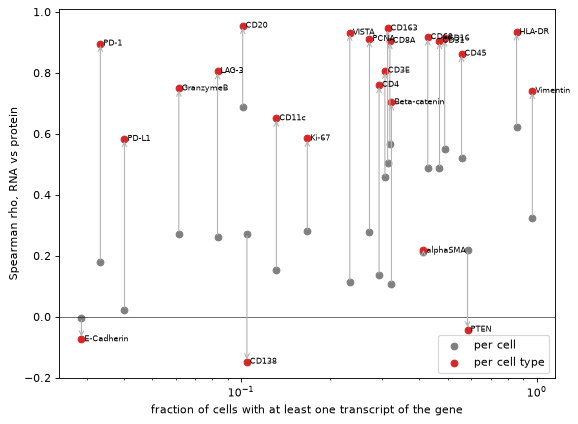

In [25]:
from scipy.stats import spearmanr

PAIRS = {"CD3E": "CD3E", "CD8A": "CD8A", "CD4": "CD4", "CD45": "PTPRC", "CD20": "MS4A1", "CD138": "SDC1",
         "CD68": "CD68", "CD163": "CD163", "CD11c": "ITGAX", "HLA-DR": "HLA-DRA", "PD-1": "PDCD1", "LAG-3": "LAG3",
         "PD-L1": "CD274", "VISTA": "VSIR", "GranzymeB": "GZMB", "Ki-67": "MKI67", "PCNA": "PCNA", "CD31": "PECAM1",
         "Vimentin": "VIM", "alphaSMA": "ACTA2", "E-Cadherin": "CDH1", "Beta-catenin": "CTNNB1", "PTEN": "PTEN",
         "CD16": "FCGR3A"}
PAIRS = {p: g for p, g in PAIRS.items() if g in rna.var_names}
counts = rna[:, list(PAIRS.values())].layers["counts"]
counts = pd.DataFrame(counts.toarray() if hasattr(counts, "toarray") else counts, columns=list(PAIRS.values()))
intensity = pd.DataFrame(prot.layers["intensity"], columns=prot.var_names)
pairs = pd.DataFrame({
    "gene": list(PAIRS.values()),
    "cells with a transcript": [(counts[g] > 0).mean() for g in PAIRS.values()],
    "cells with protein": [(intensity[p] > 0).mean() for p in PAIRS],
    "Spearman rho, per cell": [spearmanr(counts[g], intensity[p]).statistic for p, g in PAIRS.items()],
}, index=list(PAIRS))

# per cell type: the mean of each modality, compared across the cell types
type_rna = rna[:, list(PAIRS.values())].to_df().groupby(mdata.obs["cell_type"].to_numpy()).mean()
type_prot = pd.DataFrame(prot.X, columns=prot.var_names).groupby(mdata.obs["cell_type"].to_numpy()).mean()
pairs["Spearman rho, per cell type"] = [spearmanr(type_rna[g], type_prot[p]).statistic for p, g in PAIRS.items()]

fig, ax = plt.subplots(figsize=(8, 6))
for _, row in pairs.iterrows():
    ax.annotate("", xy=(row["cells with a transcript"], row["Spearman rho, per cell type"]),
                xytext=(row["cells with a transcript"], row["Spearman rho, per cell"]),
                arrowprops={"arrowstyle": "->", "color": "0.7"})
ax.scatter(pairs["cells with a transcript"], pairs["Spearman rho, per cell"], color="0.5", label="per cell")
ax.scatter(pairs["cells with a transcript"], pairs["Spearman rho, per cell type"], color="C3", label="per cell type")
for name, row in pairs.iterrows():
    ax.text(row["cells with a transcript"], row["Spearman rho, per cell type"], " " + name, fontsize=7, va="center")
ax.set(xscale="log", xlabel="fraction of cells with at least one transcript of the gene",
       ylabel="Spearman rho, RNA vs protein")
ax.axhline(0, color="k", lw=0.5)
ax.legend()
pairs.sort_values("cells with a transcript").round(2)

Per cell (grey), RNA and protein agree poorly for most pairs, and worst for the genes detected in the fewest cells:
with one or two transcripts per cell, a cell without a transcript is not a cell without the gene. Averaged per cell
type (red), the agreement is high for most pairs: the RNA is right about cell types, but too sparse to be right about
single cells. The exceptions are informative. E-cadherin transcripts are found in 3% of the cells, its protein in 89%;
ccRCC typically loses E-cadherin, and much of this stain may be background. *SDC1* (CD138) is also expressed by
epithelial cells, and PTEN and alphaSMA vary little between cell types in either modality.

### The protein finds the cells whose transcripts were missed

In [26]:
# for the markers that define a cell type: the fraction of its cells with no transcript of the gene but protein above
# the level of 95% of the other cells
DEFINING = {"CD8A": ("CD8 T",), "CD3E": ("CD8 T", "CD4 T"), "CD4": ("CD4 T",),
            "PD-1": ("CD8 T, PD-1+ LAG-3+",), "LAG-3": ("CD8 T, PD-1+ LAG-3+",), "CD20": ("B cells",),
            "CD68": ("macrophages",), "CD163": ("macrophages",), "PD-L1": ("macrophages, PD-L1+ CXCL9+",),
            "Ki-67": ("proliferating",), "CD31": ("endothelium",)}
rows = []
for protein, cell_types in DEFINING.items():
    if protein not in PAIRS:
        continue
    names = mdata.obs["cell_type"].astype(str)
    target = np.any([names.str.contains(t, regex=False) for t in cell_types], axis=0)
    threshold = np.percentile(intensity[protein][~target], 95)
    no_rna = counts[PAIRS[protein]][target] == 0
    high_protein = intensity[protein][target] > threshold
    rows.append({"protein": protein, "gene": PAIRS[protein], "cells": " + ".join(cell_types),
                 "no transcript": no_rna.mean(), "protein high": high_protein.mean(),
                 "protein high among those without a transcript": high_protein[no_rna].mean()})
pd.DataFrame(rows).set_index("protein").round(2)

,gene,cells,no transcript,protein high,protein high among those without a transcript
protein,,,,,
CD8A,CD8A,CD8 T,0.22,0.82,0.57
CD3E,CD3E,CD8 T + CD4 T,0.31,0.41,0.34
CD4,CD4,CD4 T,0.64,0.96,0.96
PD-1,PDCD1,"CD8 T, PD-1+ LAG-3+",0.90,0.79,0.79
LAG-3,LAG3,"CD8 T, PD-1+ LAG-3+",0.75,0.78,0.74
CD20,MS4A1,B cells,0.09,0.98,0.85
CD68,CD68,macrophages,0.23,0.52,0.32
CD163,CD163,macrophages,0.30,0.49,0.30
PD-L1,CD274,"macrophages, PD-L1+ CXCL9+",0.93,1.00,1.00


For the markers that define a cell type, the protein finds the cells the RNA misses. 90% of the PD-1+ LAG-3+ CD8 T
cells have no *PDCD1* transcript, yet most of those have high PD-1 protein; 93% of the PD-L1+ macrophages have no
*CD274* transcript, and all of those have high PD-L1 protein. These types were defined with the protein, so for PD-1,
LAG-3 and PD-L1 the comparison is partly circular. The CD8A and CD20 rows, for types that many other markers define,
make the same point: a fifth of the CD8 T cells have no *CD8A* transcript, and more than half of those have high
CD8A protein; 9% of the B cells have no *MS4A1* transcript, and 85% of those have high CD20 protein.

**What the protein adds**, then: on a panel this sparse, the RNA identifies cell types, but the states that matter
for immunotherapy (PD-1, LAG-3, PD-L1) are rarely seen as transcripts in a single cell. The protein measures them in
the cells that carry them.

## 8. What do the images add beyond the mean intensity?

The protein value of a cell is one number per stain: its mean intensity. The images hold more: whether a stain is
on the membrane or spread through the cell, how textured it is, how large and round the cell and its nucleus are.
[cp_measure](https://github.com/afermg/cp_measure), CellProfiler's measurements as a Python library, computes such
features per cell; squidpy runs it on the stains and the segmentation of a SpatialData object. On 28 images this gives
about 4,500 features per cell, many redundant or uninformative, so we select them with
[mantispy](https://github.com/scverse/mantispy), which applies the standard selection steps of image-based profiling
(pycytominer's).

Computing the features for all 425,000 cells takes 1.5 hours on 64 cores (`../benchmark/image_features.py`); here we
compute them for the window above.

In [27]:
import logging
import os

import mantispy as mt
import squidpy as sq

logging.getLogger("distributed").setLevel(logging.ERROR)  # the worker processes report their shutdown

# squidpy computes the features in worker processes, which read the images from a zarr store
store = Path("window.zarr")
if not store.exists():
    sd.SpatialData(images={"stains": window["stains"]}, labels={"cell_labels": window["cell_labels"]}).write(store)
CP_FEATURES = ["cp_measure:intensity", "cp_measure:sizeshape", "cp_measure:texture", "cp_measure:granularity",
               "cp_measure:radial"]
# intensity_range="auto" scales each stain to 0-1 by its own range: cp_measure's texture quantizes the image into 256
# gray levels, and a dim stain would otherwise use only one or two of them
features = sq.experimental.im.calculate_image_features(
    sd.read_zarr(store), image_key="stains", labels_key="cell_labels", scale="scale0", features=CP_FEATURES,
    intensity_range="auto", n_jobs=min(8, os.cpu_count()), inplace=False)
# the features describe the appearance of a cell: drop the ones that record its position
POSITIONAL = ("Center_", "BoundingBoxMinimum", "BoundingBoxMaximum", "Location_", "SpatialMoment_")
features = features[:, ~features.var_names.str.startswith(POSITIONAL)].copy()
cell_type = window["table"].obs.set_index("cell_labels")["cell_type"]
features.obs["cell_type"] = cell_type.reindex(features.obs["label_id"].to_numpy()).to_numpy()
features = features[features.obs["cell_type"].notna()].copy()
print(features.n_obs, "cells x", features.n_vars, "features")

no parent found for <ome_zarr.reader.Label object at 0x7f1e0e99bcb0>: None


INFO     Computing centroids from coarse scale.                                                                    


INFO     Tiling input into 4 tile(s) of size 1024 px.                                                              


tiles:   0%|          | 0/4 [00:00<?, ?it/s]

tiles:  25%|██▌       | 1/4 [02:30<07:31, 150.50s/it]

...

tiles:  75%|███████▌  | 3/4 [02:53<00:41, 41.51s/it]

tiles: 100%|██████████| 4/4 [03:17<00:00, 34.48s/it]

tiles: 100%|██████████| 4/4 [03:17<00:00, 49.36s/it]

WARNING  Dropped 144 constant feature(s) with no variance across cells.                                            


1970 cells x 4311 features


In [28]:
# z-scores per feature (median and MAD, mantispy's default, fail for sparse stains: most cells have the same value),
# then the selection: drop constant, mostly missing and redundant (|r| > 0.9 with a kept one) features
mt.pp.normalize(features, method="standardize", by=None, reference=None)
mt.pp.feature_select(features)
selected = features[:, features.var["selected"]].copy()
print(f"{selected.n_vars} of {features.n_vars} features selected; removed by each step:",
      features.uns["mantispy"]["feature_select"])


def family(name):
    if "_256" in name:  # the Haralick texture features, computed on 256 gray levels
        return "texture"
    for prefix, label in [("Intensity", "intensity"), ("Granularity", "granularity"), ("Radial", "radial distribution")]:
        if name.startswith(prefix):
            return label
    return "cell shape"


selected.var_names.map(family).value_counts().rename("selected features").to_frame().T

1867 of 4311 features selected; removed by each step: {'drop_degenerate': 0, 'variance_threshold': 0, 'correlation_threshold': 2444, 'drop_na_columns': 0, 'blocklist': 0}


,radial distribution,texture,granularity,intensity,cell shape
selected features,940,378,284,232,33


### Which image features tell cell types apart?

For the four most frequent cell types of the window, the selected features that differ most between them
(an F statistic over the cell types), excluding the plain mean intensities, which the protein table already has:

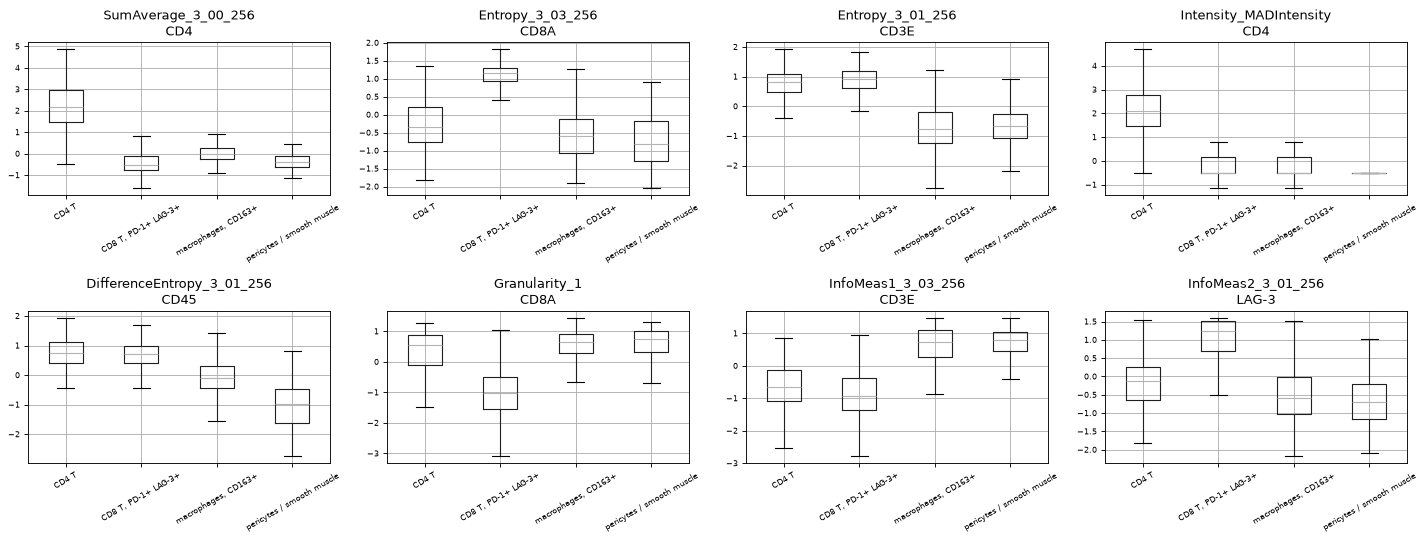

In [29]:
from sklearn.feature_selection import f_classif

common = selected.obs["cell_type"].value_counts().index[:4]
sub = selected[selected.obs["cell_type"].isin(common)]
X = np.nan_to_num(np.asarray(sub.X))
F, _ = f_classif(X, sub.obs["cell_type"].astype(str))
ranking = pd.Series(F, index=sub.var_names).drop(
    [n for n in sub.var_names if n.startswith("Intensity_MeanIntensity__")], errors="ignore").nlargest(8)
values = pd.DataFrame(X, columns=sub.var_names)[ranking.index]
values["cell type"] = sub.obs["cell_type"].astype(str).to_numpy()
fig, axs = plt.subplots(2, 4, figsize=(18, 7), sharey=False)
for ax, name in zip(axs.flat, ranking.index, strict=True):
    values.boxplot(column=name, by="cell type", ax=ax, showfliers=False, rot=30)
    ax.set(title=name.replace("__", "\n"), xlabel="")
    ax.tick_params(labelsize=7)
fig.suptitle("")
plt.tight_layout()

The features that separate the cell types best are texture and granularity features of the lineage stains: how
uneven the CD8A, CD3E, CD4 or LAG-3 signal is within a cell, not only how bright. The PD-1+ CD8 T cells, for example,
have a high entropy of the CD8A and LAG-3 stains. These are new descriptions, but of the same stains whose mean
intensity is already in the protein table, which is what the benchmark below measures.

### Do the image features improve the representation of a cell?

The benchmark asks this with the same test as before: with the image features of the DAPI, of the cell shape and of
the training stains only (never of the hidden proteins), how well does a cell's representation predict its hidden
proteins, genes and region?

In [30]:
results = pd.read_csv("../benchmark/results/results_summary.csv", index_col=0)
labels = {"rna_pca": "RNA PCA", "scvi": "scVI", "prot_markers": "protein markers", "image": "image features",
          "concat": "RNA + protein", "wnn": "WNN", "mofa": "MOFA+", "totalvi": "totalVI",
          "prot_image": "protein + image features", "rna_prot_image": "RNA + protein + image features"}
results.rename(index=labels)[["protein_r_mean", "gene_r_mean", "region_bal_acc_mean"]].set_axis(
    ["held-out protein r", "held-out gene r", "region balanced accuracy"], axis=1).sort_values("held-out protein r")

,held-out protein r,held-out gene r,region balanced accuracy
method,,,
RNA PCA,0.621,0.396,0.832
scVI,0.623,0.393,0.838
totalVI,0.636,0.403,0.848
image features,0.670,0.345,0.822
protein + image features,0.730,0.372,0.859
protein markers,0.731,0.364,0.856
MOFA+,0.745,0.422,0.888
RNA + protein,0.753,0.420,0.895
RNA + protein + image features,0.756,0.419,0.897


The images carry information: from the image features of the training stains alone, the hidden proteins of a cell
are predicted better than from any RNA representation. But little of it is new. Added to the protein markers, or to
the RNA and the markers, the image features change the scores by less than 0.01, within the spread between the
folds. On this panel, the mean intensity of a stain already says most of what its image says about a cell's type and
region; what the image adds, the shape and the texture, matters for other questions, such as a cell's state or its
morphology, more than for typing it.

A pitfall we met on the way: cp_measure computes texture on 256 gray levels, mapped from the full range of the 16-bit
image, of which these stains use a small part. Without scaling each stain to its own range first
(`intensity_range="auto"`), most cells get no texture at all.

## 9. Saving the analysis

The annotated table, the cell outlines and the pathology regions make a light SpatialData object (without the images,
which stay with the original data), which can be shared and read back with both modalities.

In [31]:
light = sd.SpatialData(shapes={"cell_boundaries": sdata["cell_boundaries"], "pathology": sdata["pathology"]},
                       labels={"cell_labels": sdata["cell_labels"]}, tables={"table": mdata})
path = Path("rcc_multimodal.zarr")
light.write(path, overwrite=True)
reread = sd.read_zarr(path)
table = reread["table"]
print(type(table).__name__, table.shape, {name: m.shape for name, m in table.mod.items()})
print(table.obs[["cell_type", "pathology"]].head())

no parent found for <ome_zarr.reader.Label object at 0x7f1de7e43110>: None


MuData (425878, 432) {'rna': (425878, 405), 'prot': (425878, 27)}
                      cell_type pathology
aaaaaglh-1  CD8 T, PD-1+ LAG-3+     Tumor
aaaadpem-1  macrophages, CD163+     Tumor
aaaafdfe-1  CD8 T, PD-1+ LAG-3+     Tumor
aaaagljm-1                tumor     Tumor
aaaahdcb-1         plasma cells     Tumor


The table read back is a MuData object with both modalities, the cell types and the pathology regions: any tool
reading SpatialData finds the RNA and the protein of each cell, next to its outline.

## Appendix: versions

In [32]:
import importlib.metadata

for package in ["spatialdata", "spatialdata-io", "spatialdata-plot", "mudata", "muon", "anndata", "scanpy",
                "scvi-tools", "mofapy2", "squidpy"]:
    print(f"{package:>16}: {importlib.metadata.version(package)}")

     spatialdata: 0.8.1.dev44+g135ac4842
  spatialdata-io: 0.1.dev1195+g523292142
spatialdata-plot: 0.4.4.dev2+g8f1637bea
          mudata: 0.4.1
            muon: 0.2.0


         anndata: 0.13.4


          scanpy: 1.12.4
      scvi-tools: 1.5.1
         mofapy2: 0.7.5


         squidpy: 0.1.dev970+gf1fdce4c8
